# TrendPulse - Part 3: Visualization, EDA and Business Thinking

## 1. Profile the data

In [1]:
import pandas as pd
import numpy as np

COUNTRIES = ["US", "GB", "IN"]

frames = []
for country in COUNTRIES:
    d = pd.read_csv(f"data/{country}videos.csv")
    d["country"] = country
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
print("Shape:", df.shape)

Shape: (46230, 15)


In [2]:
print(df.dtypes)

missing = df.isna().sum()
missing = missing[missing > 0]

report = pd.DataFrame({
    "missing_count": missing,
    "percent": (missing / len(df) * 100).round(2)
})
display(report)

video_id                   object
trending_date              object
title                      object
channel_title              object
category_id                 int64
publish_time               object
views                       int64
likes                     float64
dislikes                    int64
comment_count             float64
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                object
country                    object
dtype: object


,missing_count,percent
likes,12,0.03
comment_count,36,0.08
description,1624,3.51


In [3]:
rows_start = len(df)

# 1. fix types
df["trending_date"] = pd.to_datetime(df["trending_date"], format="%y.%d.%m")
df["publish_time"] = pd.to_datetime(df["publish_time"], utc=True).dt.tz_localize(None)

# 2. fill missing values
df["likes"] = df["likes"].fillna(0).astype("int64")
df["comment_count"] = df["comment_count"].fillna(0).astype("int64")
df["description"] = df["description"].fillna("No description")

# 3. remove duplicates
df = df.drop_duplicates(subset=["video_id", "trending_date", "country"])
rows_after_dups = len(df)

# 4. remove removed/errored videos
removed = df["video_error_or_removed"].sum()
df = df[df["video_error_or_removed"] == False].reset_index(drop=True)

print("Rows at start:           ", rows_start)
print("Duplicates removed:      ", rows_start - rows_after_dups)
print("Removed/errored videos:  ", removed)
print("Rows after cleaning:     ", len(df))

Rows at start:            46230
Duplicates removed:       230
Removed/errored videos:   92
Rows after cleaning:      45908


In [4]:
categories = pd.read_csv("data/categories.csv")[["category_id", "category_name"]]

rows_before = len(df)
df = df.merge(categories, on="category_id", how="left")

df["days_to_trend"] = (df["trending_date"] - df["publish_time"].dt.normalize()).dt.days

print("Rows before merge:", rows_before, " after:", len(df))
print("Records without a category name:", df["category_name"].isna().sum())
display(df[["title", "category_name", "views", "days_to_trend"]].head())

Rows before merge: 45908  after: 45908
Records without a category name: 0


,title,category_name,views,days_to_trend
0,Honest Football Prank LEAKED,People & Blogs,48555,0
1,Surprising Cricket Review,News & Politics,198385,2
2,Mira Solis - Football (Live) OFFICIAL,Music,231656,1
3,Zed Rivera - Space (Lyric Video)?!,Music,8083,18
4,Surprising Election Recipe,Education,373161,5


## 2. Charts (Matplotlib)

In [5]:
import matplotlib.pyplot as plt

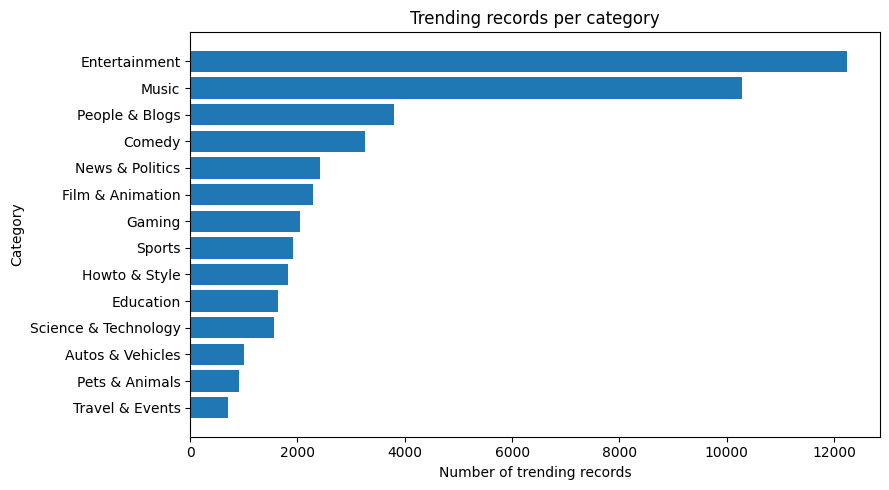

category_name
Entertainment     26.7
Music             22.4
People & Blogs     8.3
Name: count, dtype: float64


In [6]:
cat_counts = df["category_name"].value_counts()

plt.figure(figsize=(9, 5))
plt.barh(cat_counts.index[::-1], cat_counts.values[::-1])
plt.title("Trending records per category")
plt.xlabel("Number of trending records")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

print((cat_counts / len(df) * 100).round(1).head(3))

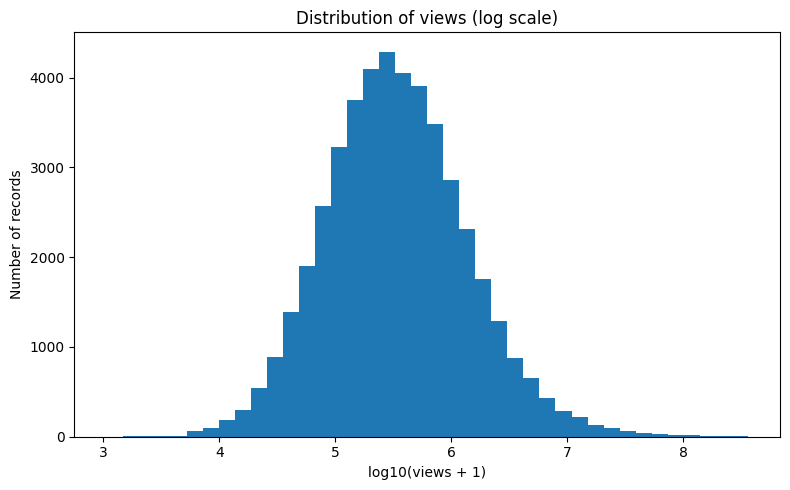

Median views: 318570.0
Mean views:   1180232


In [7]:
log_views = np.log10(df["views"] + 1)

plt.figure(figsize=(8, 5))
plt.hist(log_views, bins=40)
plt.title("Distribution of views (log scale)")
plt.xlabel("log10(views + 1)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

print("Median views:", df["views"].median())
print("Mean views:  ", round(df["views"].mean()))

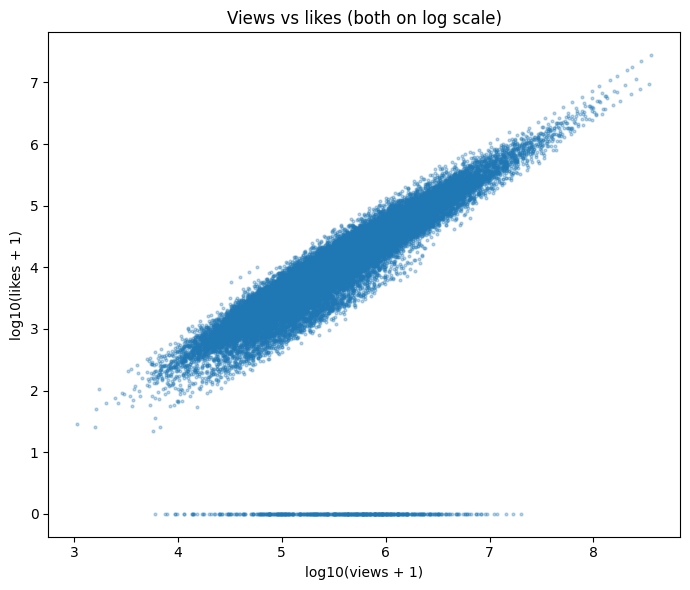

Correlation of the logged values: 0.788


In [8]:
plt.figure(figsize=(7, 6))
plt.scatter(np.log10(df["views"] + 1), np.log10(df["likes"] + 1), s=4, alpha=0.3)
plt.title("Views vs likes (both on log scale)")
plt.xlabel("log10(views + 1)")
plt.ylabel("log10(likes + 1)")
plt.tight_layout()
plt.show()

r = np.corrcoef(np.log10(df["views"] + 1), np.log10(df["likes"] + 1))[0, 1]
print("Correlation of the logged values:", round(r, 3))

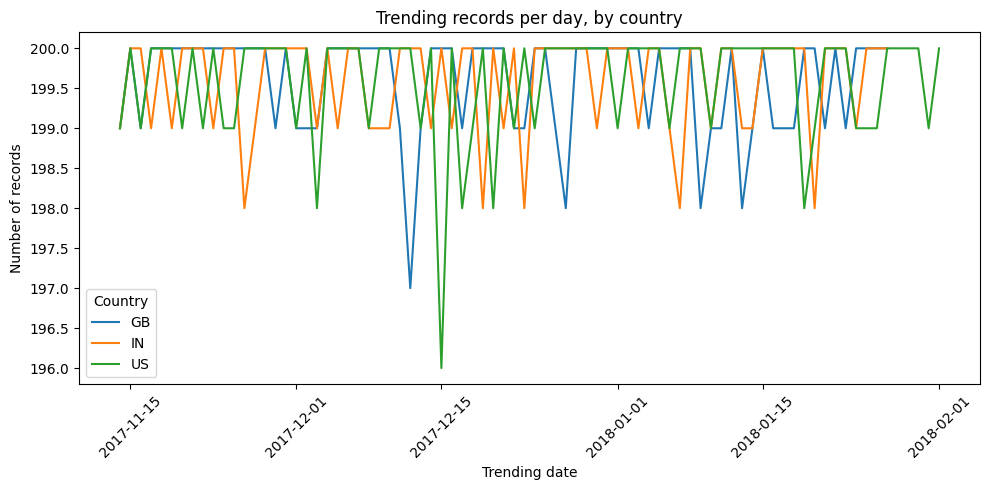

country
GB    199.6
IN    199.6
US    199.6
dtype: float64


In [9]:
daily = df.groupby(["trending_date", "country"]).size().unstack()

plt.figure(figsize=(10, 5))
for country in daily.columns:
    plt.plot(daily.index, daily[country], label=country)
plt.title("Trending records per day, by country")
plt.xlabel("Trending date")
plt.ylabel("Number of records")
plt.legend(title="Country")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(daily.mean().round(1))

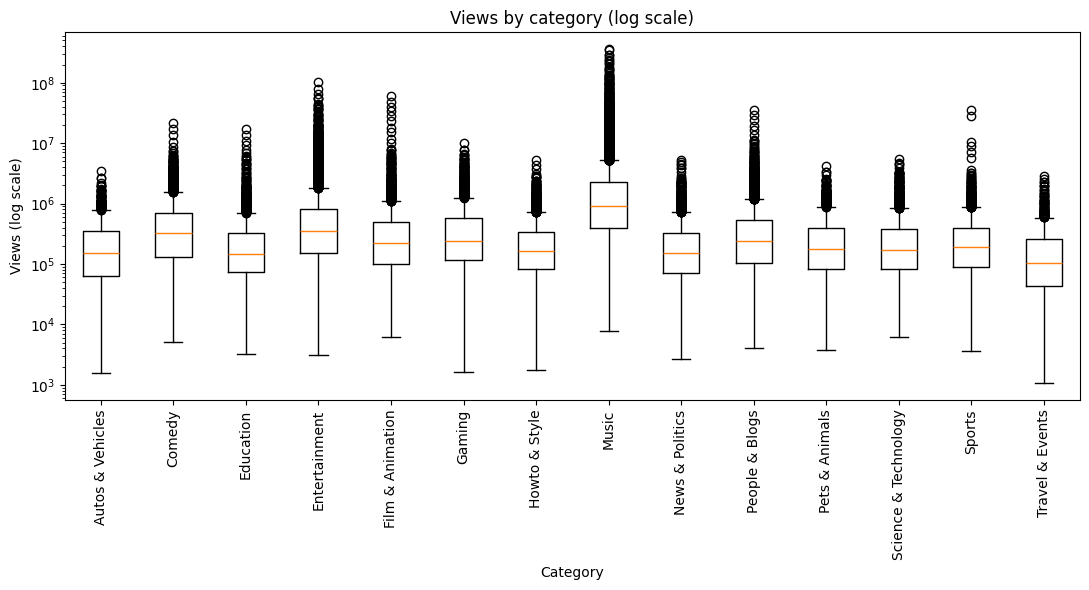

category_name
Music                   916774.0
Entertainment           354636.0
Comedy                  320455.0
Gaming                  243720.0
People & Blogs          240397.0
Film & Animation        218812.0
Sports                  189716.0
Pets & Animals          176708.0
Science & Technology    171824.0
Howto & Style           166926.0
Autos & Vehicles        153683.0
News & Politics         151220.0
Education               148809.0
Travel & Events         104042.0
Name: views, dtype: float64


In [10]:
names = sorted(df["category_name"].unique())
data = [df.loc[df["category_name"] == n, "views"] for n in names]

plt.figure(figsize=(11, 6))
plt.boxplot(data)
plt.yscale("log")
plt.xticks(range(1, len(names) + 1), names, rotation=90)
plt.title("Views by category (log scale)")
plt.xlabel("Category")
plt.ylabel("Views (log scale)")
plt.tight_layout()
plt.show()

print(df.groupby("category_name")["views"].median().sort_values(ascending=False).round(0))

## 3. Interactive charts (Plotly)

In [11]:
import plotly.express as px

sample = df[df["likes"] > 0].sample(5000, random_state=42)

fig = px.scatter(
    sample, x="views", y="likes",
    color="category_name", hover_name="title",
    log_x=True, log_y=True, opacity=0.6,
    title="Views vs likes by category (random sample of 5,000 videos)",
    labels={"views": "Views (log scale)", "likes": "Likes (log scale)",
            "category_name": "Category"}
)
fig.show()

In [12]:
avg = df.groupby(["category_name", "country"])["views"].mean().round(0).reset_index()

fig = px.bar(
    avg, x="category_name", y="views", color="country", barmode="group",
    title="Average views per category, by country",
    labels={"category_name": "Category", "views": "Average views", "country": "Country"}
)
fig.show()

print(avg.pivot(index="category_name", columns="country", values="views"))

country                      GB         IN         US
category_name                                        
Autos & Vehicles       222282.0   329029.0   297133.0
Comedy                 505533.0   721860.0   585808.0
Education              257606.0   490151.0   310393.0
Entertainment          818040.0   966237.0   881302.0
Film & Animation       799987.0   552891.0   411307.0
Gaming                 495207.0   578939.0   464046.0
Howto & Style          218785.0   371885.0   314357.0
Music                 3729081.0  2451013.0  2870471.0
News & Politics        233976.0   346217.0   225068.0
People & Blogs         438971.0   561789.0   646617.0
Pets & Animals         273564.0   386281.0   390569.0
Science & Technology   332917.0   395586.0   338091.0
Sports                 283000.0   535206.0   326692.0
Travel & Events        222283.0   281037.0   198943.0


## 5. Distributions and outliers

In [13]:
def distribution_report(series, name):
    mean = series.mean()
    median = series.median()
    mode = series.mode()[0]

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((series < lower) | (series > upper)).sum()

    print(f"--- {name} ---")
    print(f"Mean:   {mean:,.0f}")
    print(f"Median: {median:,.0f}")
    print(f"Mode:   {mode:,.0f}")
    print(f"Q1: {q1:,.0f}   Q3: {q3:,.0f}   IQR: {iqr:,.0f}")
    print(f"Outlier limits: {lower:,.0f} to {upper:,.0f}")
    print(f"Outliers: {outliers:,} ({outliers / len(series) * 100:.1f}% of records)")
    print(f"Largest value: {series.max():,.0f}")
    print()

distribution_report(df["views"], "Views")
distribution_report(df["likes"], "Likes")

--- Views ---
Mean:   1,180,232
Median: 318,570
Mode:   16,000
Q1: 129,578   Q3: 823,936   IQR: 694,357
Outlier limits: -911,957 to 1,865,472
Outliers: 5,073 (11.1% of records)
Largest value: 360,760,164

--- Likes ---
Mean:   45,861
Median: 10,206
Mode:   0
Q1: 3,652   Q3: 28,986   IQR: 25,334
Outlier limits: -34,348 to 66,986
Outliers: 5,255 (11.4% of records)
Largest value: 27,537,822



## 6. Correlation

,views,likes,dislikes,comment_count,days_to_trend
views,1.00,0.92,0.89,0.92,0.20
likes,0.92,1.00,0.87,0.81,0.16
dislikes,0.89,0.87,1.00,0.89,0.20
comment_count,0.92,0.81,0.89,1.00,0.21
days_to_trend,0.20,0.16,0.20,0.21,1.00


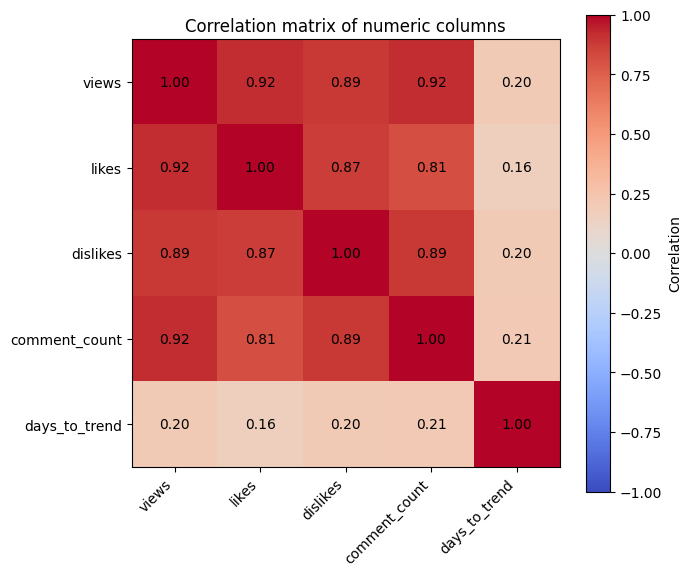

In [14]:
cols = ["views", "likes", "dislikes", "comment_count", "days_to_trend"]
corr = df[cols].corr()
display(corr.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, label="Correlation")
ax.set_title("Correlation matrix of numeric columns")
plt.tight_layout()
plt.show()

In [15]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack()

top2 = pairs.abs().sort_values(ascending=False).head(2)
for (a, b) in top2.index:
    print(f"{a} and {b}: {pairs[(a, b)]:.3f}")

views and likes: 0.921
views and comment_count: 0.916


## 7. Funnel analysis

In [16]:
videos = df.groupby("video_id").agg(
    peak_views=("views", "max"),
    peak_comments=("comment_count", "max")
).reset_index()

print("Unique videos:", len(videos))

Unique videos: 14688


In [17]:
median_peak = videos["peak_views"].median()
p90_peak = videos["peak_views"].quantile(0.90)

stage1 = videos
stage2 = stage1[stage1["peak_views"] > median_peak]
stage3 = stage2[stage2["peak_views"] > p90_peak]
stage4 = stage3[stage3["peak_comments"] >= 1000]

funnel = pd.DataFrame({
    "stage": ["1. All videos that trended",
              "2. Above median peak views",
              "3. Above 90th percentile peak views",
              "4. With 1,000+ comments"],
    "videos": [len(stage1), len(stage2), len(stage3), len(stage4)]
})

funnel["conversion_from_previous_%"] = (funnel["videos"] / funnel["videos"].shift(1) * 100).round(1)
funnel["share_of_all_%"] = (funnel["videos"] / funnel["videos"].iloc[0] * 100).round(1)

display(funnel)

drop = 100 - funnel["conversion_from_previous_%"]
biggest = drop.idxmax()
print("Largest drop-off is into:", funnel.loc[biggest, "stage"],
      f"({drop[biggest]:.1f}% of the previous stage was lost)")
print("Median peak views:", round(median_peak), " 90th percentile:", round(p90_peak))

,stage,videos,conversion_from_previous_%,share_of_all_%
0,1. All videos that trended,14688,NaN,100.0
1,2. Above median peak views,7344,50.0,50.0
2,3. Above 90th percentile peak views,1469,20.0,10.0
3,"4. With 1,000+ comments",1440,98.0,9.8


Largest drop-off is into: 3. Above 90th percentile peak views (80.0% of the previous stage was lost)
Median peak views: 265290  90th percentile: 1646845


## 8. Retention (trending lifespan)

In [18]:
df["first_day"] = df.groupby(["country", "video_id"])["trending_date"].transform("min")
df["day_n"] = (df["trending_date"] - df["first_day"]).dt.days + 1

display(df[["country", "video_id", "trending_date", "first_day", "day_n"]].head())

,country,video_id,trending_date,first_day,day_n
0,US,g_N-w8LeAi8,2017-11-14,2017-11-14,1
1,US,Ugyql2NlPAd,2017-11-14,2017-11-14,1
2,US,8fE19jkxJ9n,2017-11-14,2017-11-14,1
3,US,WOY0nn7HCsO,2017-11-14,2017-11-14,1
4,US,2Lc_Cs5VVr_,2017-11-14,2017-11-14,1


In [19]:
days = [1, 2, 3, 4, 5, 6, 7]
last_date = df["trending_date"].max()

videos_r = df.groupby(["country", "video_id"]).agg(
    first_day=("first_day", "first"),
    category_name=("category_name", "first")
)

presence = (df[df["day_n"].isin(days)]
            .assign(on=1)
            .pivot_table(index=["country", "video_id"], columns="day_n",
                         values="on", aggfunc="max", fill_value=0)
            .reindex(columns=days, fill_value=0))

data = videos_r.join(presence).fillna(0).reset_index()

cutoff = last_date - pd.Timedelta(days=6)
data = data[data["first_day"] <= cutoff]

print("Videos in the retention analysis:", len(data))
print("Last date in the data:", last_date.date(), "  cutoff for first day:", cutoff.date())

Videos in the retention analysis: 14531
Last date in the data: 2018-02-01   cutoff for first day: 2018-01-26


In [20]:
overall = (data[days].mean() * 100).round(1)
print("Overall retention (% of videos still trending):")
print(overall.loc[[1, 2, 3, 5, 7]])

by_country = (data.groupby("country")[days].mean() * 100).round(1)
display(by_country[[1, 2, 3, 5, 7]])

by_category = (data.groupby("category_name")[days].mean() * 100).round(1)
display(by_category[[1, 2, 3, 5, 7]].sort_values(7, ascending=False))

Overall retention (% of videos still trending):
1    100.0
2     63.7
3     42.3
5     19.7
7     10.0
dtype: float64


,1,2,3,5,7
country,,,,,
GB,100.0,69.8,49.8,26.2,14.4
IN,100.0,57.6,35.2,13.9,5.7
US,100.0,65.8,44.7,21.1,11.6


,1,2,3,5,7
category_name,,,,,
Music,100.0,81.1,66.0,43.8,29.8
Entertainment,100.0,70.8,51.5,26.9,13.6
Film & Animation,100.0,62.1,40.9,15.9,7.3
Comedy,100.0,65.7,42.5,17.3,7.0
People & Blogs,100.0,63.5,42.1,16.2,6.9
Gaming,100.0,62.7,39.8,14.2,6.1
Education,100.0,57.8,33.8,13.0,5.0
Autos & Vehicles,100.0,58.1,33.0,10.9,5.0
Howto & Style,100.0,59.1,33.8,11.9,3.9


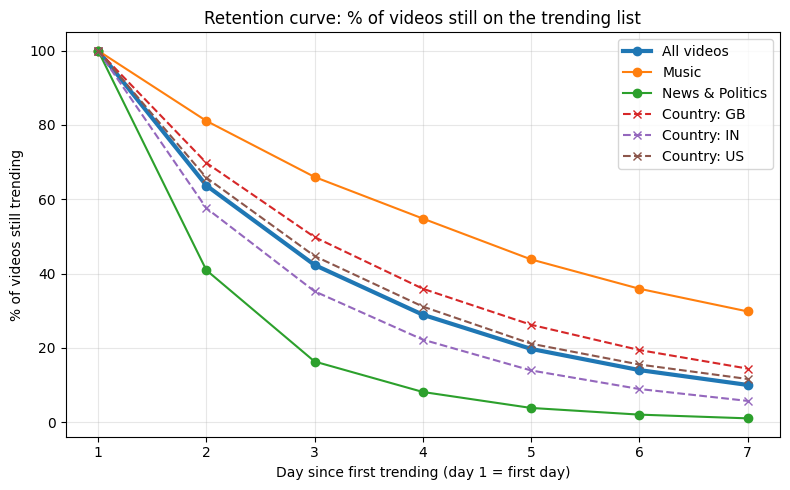

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(days, overall.values, marker="o", linewidth=3, label="All videos")
for name in ["Music", "News & Politics"]:
    plt.plot(days, by_category.loc[name].values, marker="o", label=name)
for country in by_country.index:
    plt.plot(days, by_country.loc[country].values, marker="x", linestyle="--", label=f"Country: {country}")

plt.title("Retention curve: % of videos still on the trending list")
plt.xlabel("Day since first trending (day 1 = first day)")
plt.ylabel("% of videos still trending")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Cohort view

In [22]:
video_cohort = df.groupby(["country", "video_id"]).agg(
    first_day=("trending_date", "min"),
    peak_views=("views", "max"),
    lifespan=("trending_date", "nunique")
).reset_index()

video_cohort["cohort_week"] = video_cohort["first_day"].dt.to_period("W").dt.start_time

cohorts = video_cohort.groupby("cohort_week").agg(
    videos=("video_id", "count"),
    avg_peak_views=("peak_views", "mean"),
    median_peak_views=("peak_views", "median"),
    avg_lifespan=("lifespan", "mean")
).round(1)

display(cohorts)

,videos,avg_peak_views,median_peak_views,avg_lifespan
cohort_week,,,,
2017-11-13,1607,1059522.0,266286.0,3.2
2017-11-20,1326,1246998.1,269650.5,3.2
2017-11-27,1318,1105586.0,260651.5,3.1
2017-12-04,1323,841226.8,275461.0,3.2
2017-12-11,1327,1223117.8,271502.0,3.1
2017-12-18,1375,903200.7,268899.0,3.1
2017-12-25,1297,925303.9,273822.0,3.1
2018-01-01,1349,1268136.6,246165.0,3.1
2018-01-08,1356,833168.1,281117.5,3.1


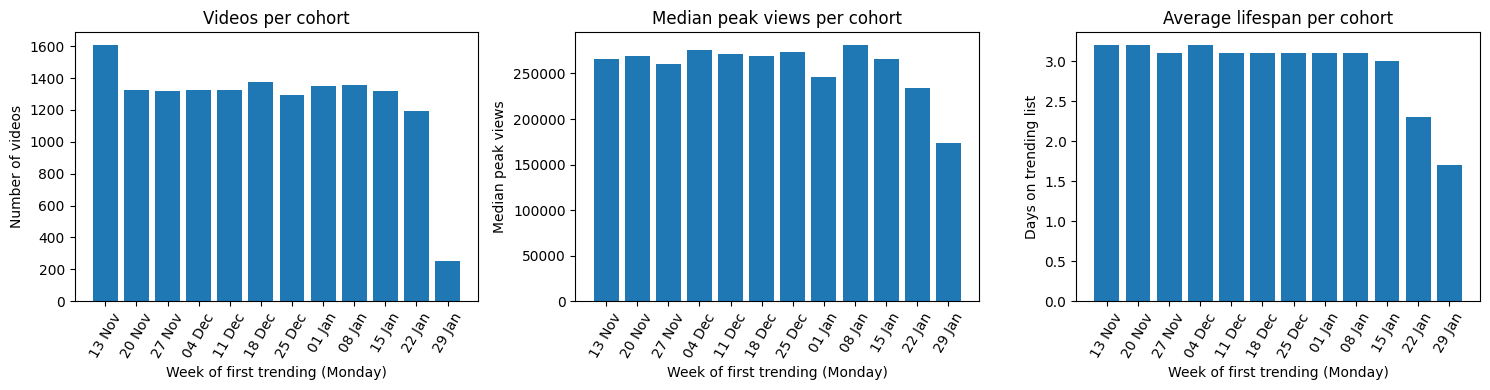

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = [d.strftime("%d %b") for d in cohorts.index]

axes[0].bar(labels, cohorts["videos"])
axes[0].set_title("Videos per cohort")
axes[0].set_ylabel("Number of videos")

axes[1].bar(labels, cohorts["median_peak_views"])
axes[1].set_title("Median peak views per cohort")
axes[1].set_ylabel("Median peak views")

axes[2].bar(labels, cohorts["avg_lifespan"])
axes[2].set_title("Average lifespan per cohort")
axes[2].set_ylabel("Days on trending list")

for ax in axes:
    ax.set_xlabel("Week of first trending (Monday)")
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 10. Content strategy briefing

In [24]:
# 1. dominant categories
share = (df["category_name"].value_counts(normalize=True) * 100).round(1)
print("Top 3 category shares (% of records):")
print(share.head(3))

# 2. how quickly videos reach trending
print("\ndays_to_trend median:", df["days_to_trend"].median())
print("Share of records that trended within 3 days:",
      round((df["days_to_trend"] <= 3).mean() * 100, 1), "%")

# 3. stay vs vanish
stay = video_cohort[video_cohort["lifespan"] >= 5]
gone = video_cohort[video_cohort["lifespan"] == 1]
print("\nVideos with lifespan >= 5 days:", len(stay), " median peak views:", round(stay["peak_views"].median()))
print("Videos with lifespan = 1 day:  ", len(gone), " median peak views:", round(gone["peak_views"].median()))

# 4. countries
print("\nAverage views by country:")
print(df.groupby("country")["views"].mean().round(0))

Top 3 category shares (% of records):
category_name
Entertainment     26.7
Music             22.4
People & Blogs     8.3
Name: proportion, dtype: float64

days_to_trend median: 3.0
Share of records that trended within 3 days: 55.3 %

Videos with lifespan >= 5 days: 2884  median peak views: 844306
Videos with lifespan = 1 day:   5586  median peak views: 170342

Average views by country:
country
GB    1583959.0
IN     953217.0
US    1014564.0
Name: views, dtype: float64
